In [33]:
import yfinance as yf
# from yahooquery import Ticker
import requests
import matplotlib.pyplot as plt
import numpy as np
import math
import pickle
from datetime import datetime

In [34]:
def time_elapsed(start_time, end_time):
    if not isinstance(start_time, datetime) or not isinstance(end_time, datetime):
        return None
    elapsed_time = end_time - start_time
    return elapsed_time.days  # Return the number of days

In [35]:
stock_ticker = ['WAT', 'GMAB', 'SKHY', 'ADI', 'TXN', 'CRL', 'JCI', 'TDY']

In [36]:
stock_name = yf.download(stock_ticker, start='2009-01-01', auto_adjust=False)

stock_info = {}
for ticker_symbol in stock_ticker if isinstance(stock_ticker, (list, tuple)) else [stock_ticker]:
    try:
        info = yf.Ticker(ticker_symbol).info
        stock_info[ticker_symbol] = info
        print(f"Stock: {info.get('longName', ticker_symbol)} ({ticker_symbol})")
    except Exception as e:
        print(f"Could not fetch company name for {ticker_symbol}: {e}")


c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
[                       0%                       ]c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.

Stock: Waters Corporation (WAT)
Stock: Genmab A/S (GMAB)
Stock: SK hynix Inc. (SKHY)
Stock: Analog Devices, Inc. (ADI)
Stock: Texas Instruments Incorporated (TXN)
Stock: Charles River Laboratories International, Inc. (CRL)
Stock: Johnson Controls International plc (JCI)
Stock: Teledyne Technologies Incorporated (TDY)


In [37]:
display(stock_name)

Price        Adj Close                                                 \
Ticker             ADI         CRL       GMAB         JCI        SKHY   
Date                                                                    
2009-01-02   13.039448   26.889999        NaN    7.218472         NaN   
2009-01-05   12.973158   26.440001        NaN    7.405756         NaN   
2009-01-06   13.602926   26.000000        NaN    7.799372         NaN   
2009-01-07   13.092482   24.820000        NaN    7.386708         NaN   
2009-01-08   13.105741   24.070000        NaN    7.545425         NaN   
...                ...         ...        ...         ...         ...   
2026-10-23  391.070007  345.369995  43.790001  143.960007  137.020004   
2026-10-26  407.929993  357.269989  44.685001  147.500000  142.619995   
2026-10-27  425.350006  358.839996  44.669998  155.880005  145.360001   
2026-10-28  428.269989  373.980011  57.290001  157.350006  164.699997   
2026-10-29  429.059998  377.899994  56.320000  157.065002  162.985001   

Price                                                Close              ...  \
Ticker             TDY         TXN         WAT         ADI         CRL  ...   
Date                                                                    ...   
2009-01-02   45.310001   10.154943   38.090000   19.670000   26.889999  ...   
2009-01-05   46.119999   10.040983   38.299999   19.570000   26.440001  ...   
2009-01-06   46.220001   10.414510   39.020000   20.520000   26.000000  ...   
2009-01-07   43.250000    9.863712   38.040001   19.750000   24.820000  ...   
2009-01-08   43.419998    9.673784   36.490002   19.770000   24.070000  ...   
...                ...         ...         ...         ...         ...  ...   
2026-10-23  625.409973  284.690002  453.670013  391.070007  345.369995  ...   
2026-10-26  645.469971  298.119995  455.980011  407.929993  357.269989  ...   
2026-10-27  654.989990  308.910004  468.549988  425.350006  358.839996  ...   
2026-10-28  665.559998  309.829987  476.880005  428.269989  373.980011  ...   
2026-10-29  677.409973  308.945007  480.964996  429.059998  377.899994  ...   

Price             Open               Volume                                \
Ticker             TXN         WAT      ADI      CRL        GMAB      JCI   
Date                                                                        
2009-01-02   15.500000   36.700001  3264900   548500         NaN  5626258   
2009-01-05   15.900000   37.980000  4380100  1178700         NaN  9290262   
2009-01-06   15.960000   38.450001  5710900  1351900         NaN  7814440   
2009-01-07   16.000000   38.320000  4462900  1422800         NaN  6736102   
2009-01-08   15.520000   37.310001  3763200  1277900         NaN  4376555   
...                ...         ...      ...      ...         ...      ...   
2026-10-23  277.869995  458.160004  2484500   822300  12999000.0  3375000   
2026-10-26  288.920013  455.980011  3810700  1175900   7473300.0  4087400   
2026-10-27  300.869995  454.829987  4082500  1159300   4929000.0  6069400   
2026-10-28  308.790009  468.019989  3886200  1299300  29281100.0  5452100   
2026-10-29  306.029999  479.230011   849542   307376   4047776.0  1050880   

Price                                              
Ticker            SKHY     TDY       TXN      WAT  
Date                                               
2009-01-02         NaN  253900  15194500   725700  
2009-01-05         NaN  403900  11656300  1185400  
2009-01-06         NaN  297200  14433000  1417800  
2009-01-07         NaN  406400  13510100   867800  
2009-01-08         NaN  296600  11072500  2158400  
...                ...     ...       ...      ...  
2026-10-23  16311700.0  368600   7512400   907600  
2026-10-26  17139300.0  443300   7594200   909100  
2026-10-27  26667700.0  254000   8160900   797300  
2026-10-28  49486400.0  321700   7355100   872500  
2026-10-29  12159957.0  107204   1436463   377719  

[4484 rows x 48 columns]

In [38]:
simulation_ticker = stock_ticker[0] if isinstance(stock_ticker, (list, tuple)) else stock_ticker
close_prices = stock_name[('Close', simulation_ticker)].dropna()

In [39]:
display(close_prices)

Date
2009-01-02     38.090000
2009-01-05     38.299999
2009-01-06     39.020000
2009-01-07     38.040001
2009-01-08     36.490002
                 ...    
2026-10-23    453.670013
2026-10-26    455.980011
2026-10-27    468.549988
2026-10-28    476.880005
2026-10-29    480.964996
Name: (Close, WAT), Length: 4484, dtype: float64

In [40]:
# Total growth = last price / first price
total_growth = close_prices.iloc[-1] / close_prices.iloc[0]

In [41]:
print(total_growth)

12.627067325049962


In [42]:
# Current price / first record (e.g., price at the beginning of 2009)
# provides us with the total growth %

# Next, we want to annualize this percentage
# First, we convert our time elapsed to the number of years elapsed
number_of_days = time_elapsed(stock_name.index[0], stock_name.index[-1])
number_of_years = number_of_days / 365.0  # Assuming 365 days per year

In [43]:
print(number_of_days)
print(number_of_years)

6509
17.832876712328765


In [44]:
print(stock_name.index[0])
print(stock_name.index[-1])

2009-01-02 00:00:00
2026-10-29 00:00:00


In [45]:
simulation_ticker = stock_ticker[0] if isinstance(stock_ticker, (list, tuple)) else stock_ticker
close_prices = stock_name[('Close', simulation_ticker)].dropna()

# Second, we can raise the total growth to the inverse of the number of years
# (e.g., ~1/10 at the time of writing) to annualize our growth rate
cagr = (close_prices.iloc[-1] / close_prices.iloc[0]) ** (1/number_of_years) - 1

# Calculate the annualized standard deviation of daily price changes.
number_of_trading_days = 252
std_dev = close_prices.pct_change().std() * math.sqrt(number_of_trading_days)

# Guard against missing data or a zero-priced series.
if close_prices.empty or not np.isfinite(cagr) or not np.isfinite(std_dev):
    raise ValueError(f"Cannot simulate {simulation_ticker}: insufficient or invalid price data")

# Calculate daily return percentages for 1 year's worth of trading (252 days).
daily_return_percentages = np.random.normal(
    cagr / number_of_trading_days,
    std_dev / math.sqrt(number_of_trading_days),
    number_of_trading_days
) + 1

# Apply the daily returns to the most recent price as a random walk.
price_series = [float(close_prices.iloc[-1])]
for daily_return in daily_return_percentages:
    price_series.append(price_series[-1] * daily_return)

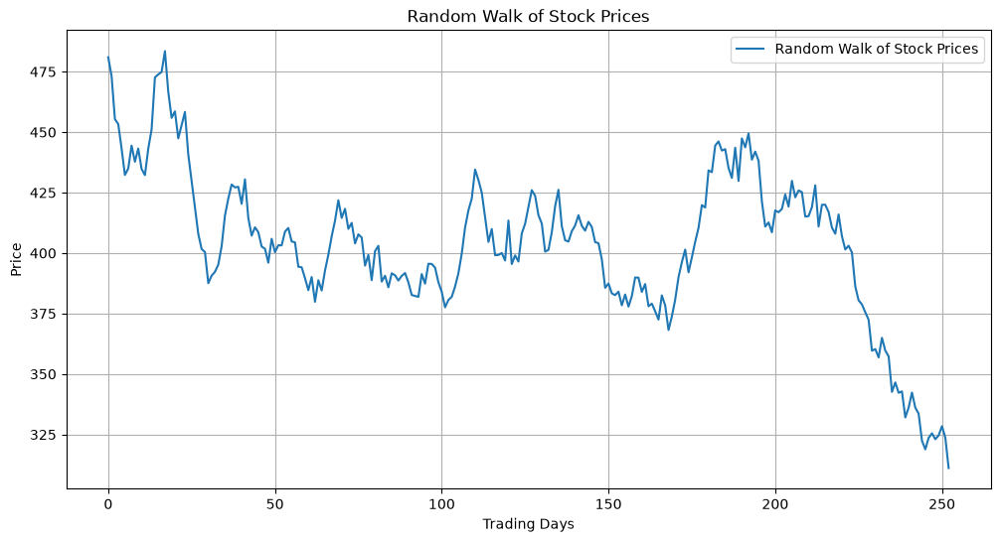

In [46]:
# Plot a single 'random walk' of stock prices
plt.figure(figsize=(12, 6))
plt.plot(price_series, label='Random Walk of Stock Prices')
plt.xlabel('Trading Days')
plt.ylabel('Price')
plt.title('Random Walk of Stock Prices')
plt.legend()
plt.grid(True)
plt.show()

# Now that we've created a single random walk above,
# we can simulate this process over a large sample size to
# get a better sense of the true expected distribution
number_of_trials = 3000

# Set up an additional array to collect all possible
# closing prices on the last day of the window.
# We can use this for a histogram to get a clearer sense of possible outcomes
closing_prices = []


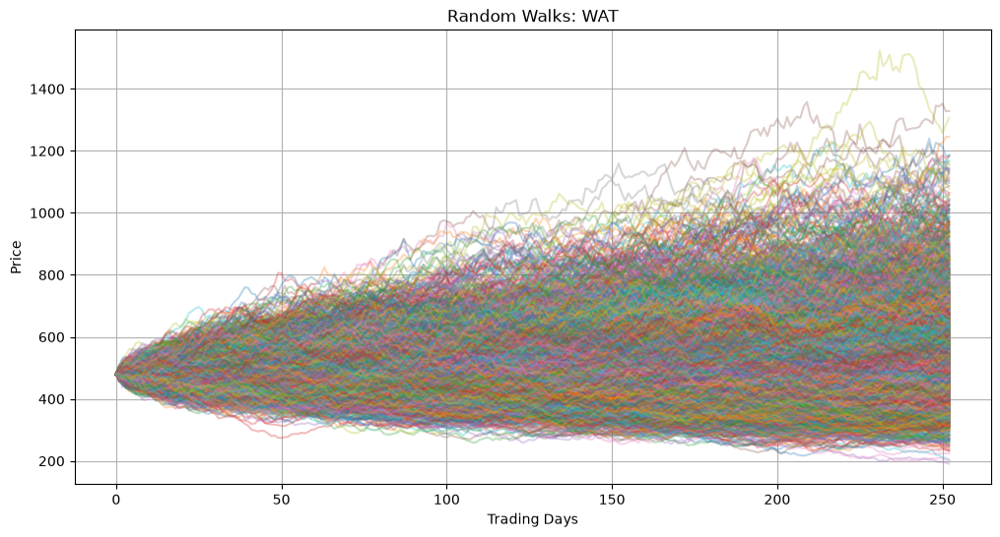

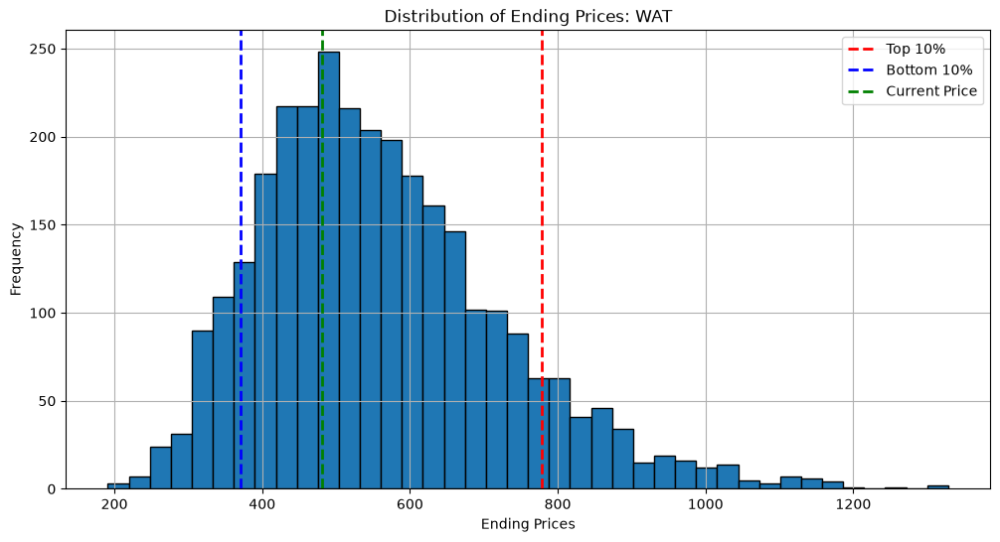

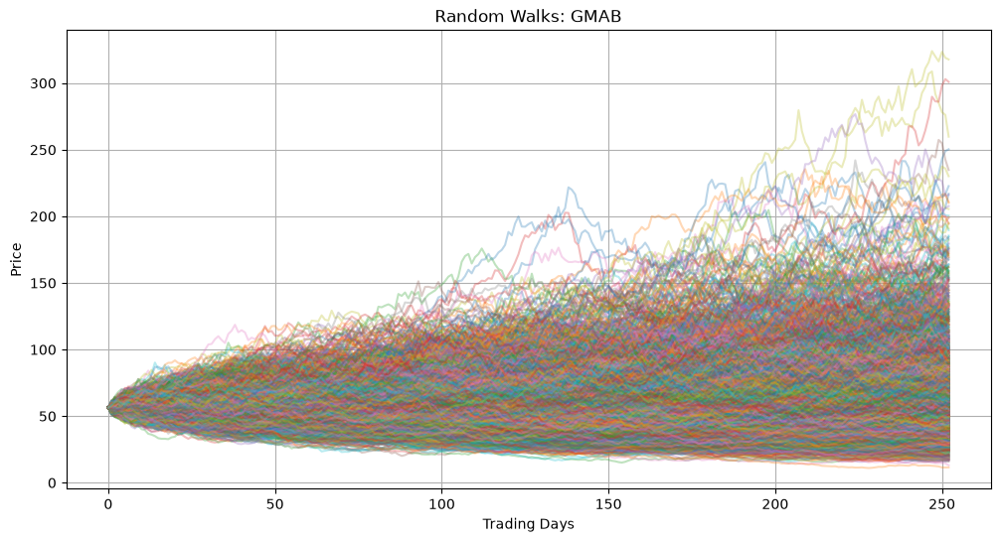

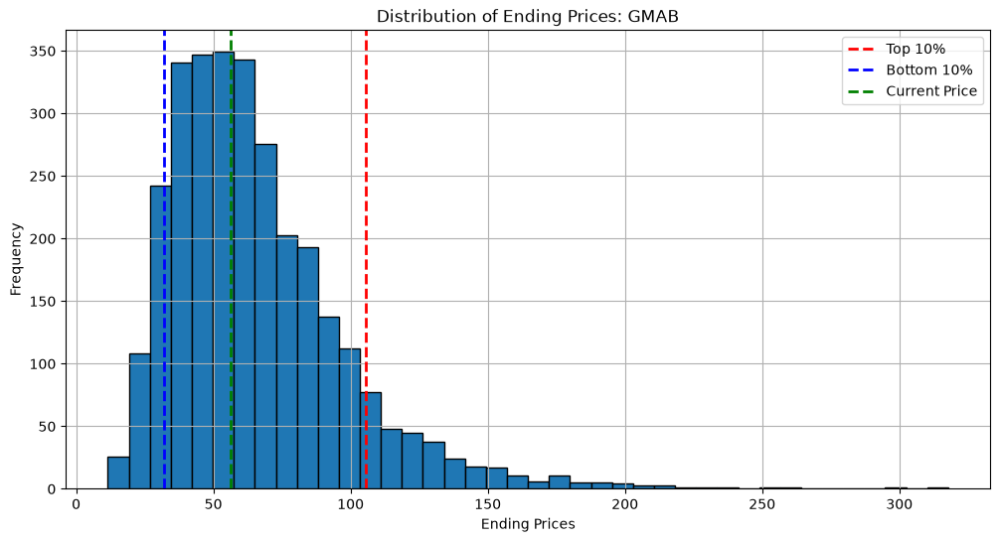

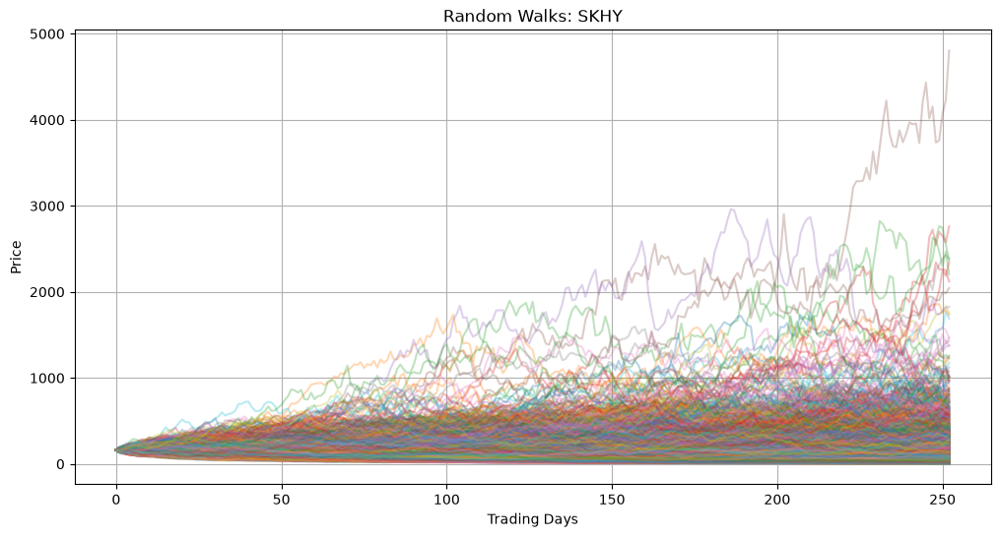

...

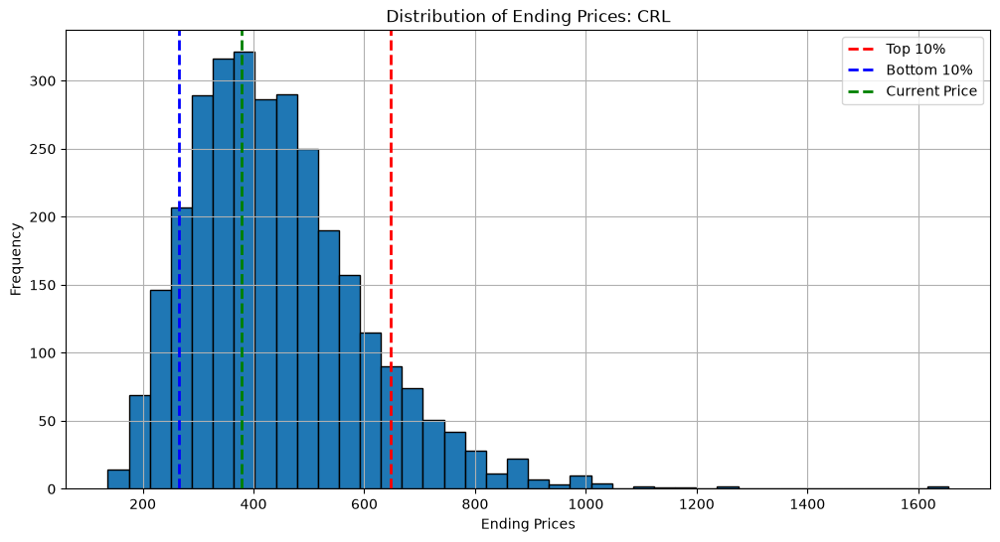

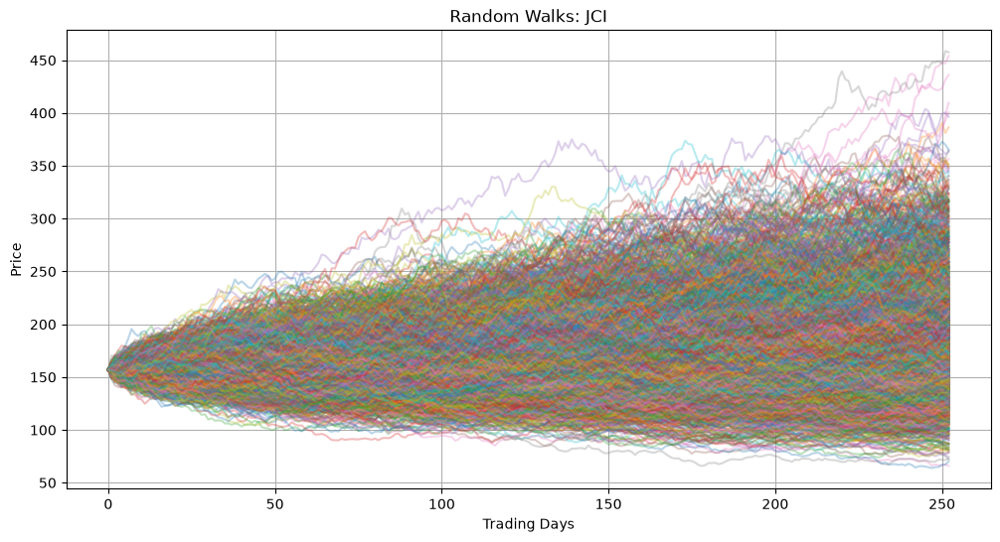

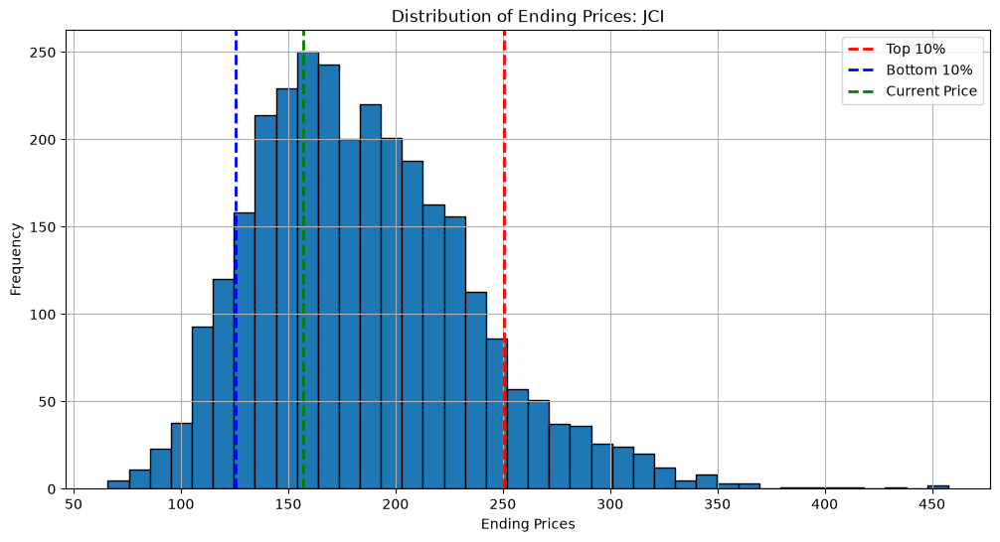

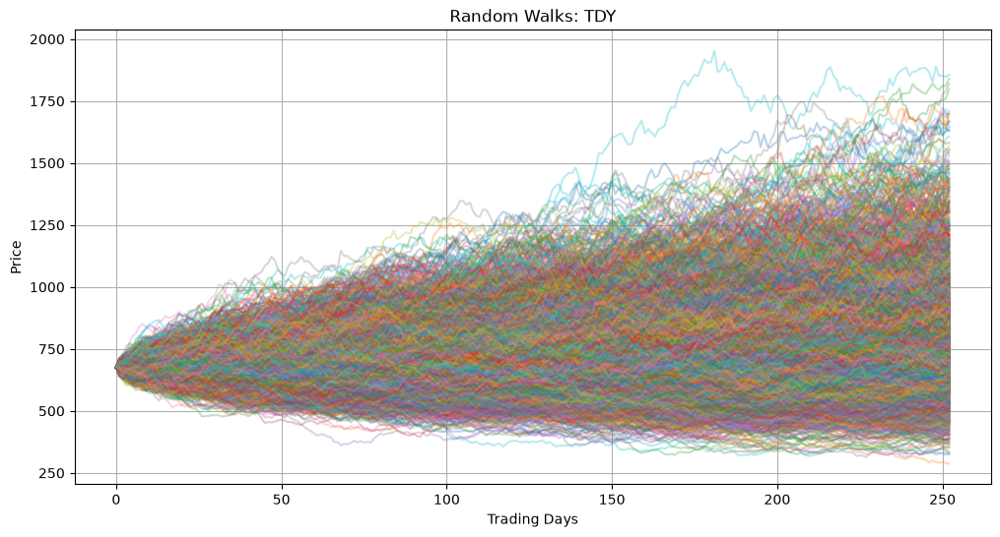

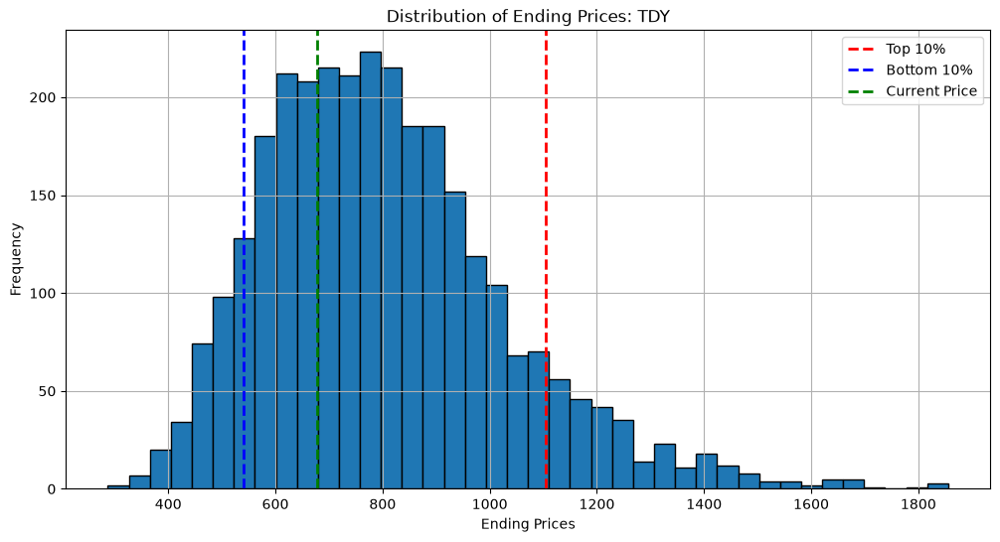

Simulated tickers: WAT, GMAB, SKHY, ADI, TXN, CRL, JCI, TDY


In [47]:
number_of_trials = 3000
number_of_trading_days = 252
simulation_results = {}

for ticker in stock_ticker:
    series = stock_name[('Close', ticker)].dropna()
    if series.empty:
        print(f'Skipping {ticker}: no price data')
        continue

    cagr = (series.iloc[-1] / series.iloc[0]) ** (1 / number_of_years) - 1
    std_dev = series.pct_change().std() * math.sqrt(number_of_trading_days)
    if not np.isfinite(cagr) or not np.isfinite(std_dev):
        print(f'Skipping {ticker}: invalid simulation parameters')
        continue

    ticker_closing_prices = []
    plt.figure(figsize=(12, 6))
    for i in range(number_of_trials):
        daily_returns = np.random.normal(
            cagr / number_of_trading_days,
            std_dev / math.sqrt(number_of_trading_days),
            number_of_trading_days
        ) + 1
        price_series = [float(series.iloc[-1])]
        for daily_return in daily_returns:
            price_series.append(price_series[-1] * daily_return)
        ticker_closing_prices.append(price_series[-1])
        plt.plot(price_series, alpha=0.3)

    plt.title(f'Random Walks: {ticker}')
    plt.xlabel('Trading Days')
    plt.ylabel('Price')
    plt.grid(True)
    plt.show()

    bottom_ten = float(np.percentile(ticker_closing_prices, 10))
    top_ten = float(np.percentile(ticker_closing_prices, 90))
    current_ticker_price = float(series.iloc[-1])

    plt.figure(figsize=(12, 6))
    plt.hist(ticker_closing_prices, bins=40, edgecolor='black')
    plt.axvline(top_ten, color='r', linestyle='dashed', linewidth=2, label='Top 10%')
    plt.axvline(bottom_ten, color='b', linestyle='dashed', linewidth=2, label='Bottom 10%')
    plt.axvline(current_ticker_price, color='g', linestyle='dashed', linewidth=2, label='Current Price')
    plt.xlabel('Ending Prices')
    plt.ylabel('Frequency')
    plt.title(f'Distribution of Ending Prices: {ticker}')
    plt.legend()
    plt.grid(True)
    plt.savefig(f'histogram_{ticker}.png')
    plt.show()

    simulation_results[ticker] = {
        'closing_prices': ticker_closing_prices,
        'mean_end_price': float(np.mean(ticker_closing_prices)),
        'top_ten': float(np.percentile(ticker_closing_prices, 90)),
        'bottom_ten': float(np.percentile(ticker_closing_prices, 10)),
        'current_price': float(series.iloc[-1])
    }

# The simulation variables are stored by ticker; WAT is intentionally not selected here.
closing_prices_by_ticker = {
    ticker: result['closing_prices']
    for ticker, result in simulation_results.items()
}
print('Simulated tickers:', ', '.join(simulation_results.keys()))


In [48]:
# Store the data in a pickle file
data_to_pickle = {
    #'apple_data': apple,
    'closing_prices': closing_prices,
    'mean_end_price': mean_end_price,
    'top_ten_percentile': top_ten,
    'bottom_ten_percentile': bottom_ten,
}

pickle_file_path = 'stock_simulation_data_amd.pkl'

with open(pickle_file_path, 'wb') as pickle_file:
    pickle.dump(data_to_pickle, pickle_file)

print(f'Data has been saved to {pickle_file_path}')


Data has been saved to stock_simulation_data_amd.pkl


In [49]:
import pandas as pd
target_date = stock_name.index[-1] + pd.tseries.offsets.BDay(252)
print("Last data date:", stock_name.index[-1].date())
print("Expected price is for approx.:", target_date.date())
print("Expected price:", mean_end_price)

Last data date: 2026-10-29
Expected price is for approx.: 2027-10-18
Expected price: 560.3


# Enhanced Monte Carlo Simulation
## Incorporating Fundamentals, Analyst Price Targets & 1-Year Projection

The basic model above uses only historical drift (CAGR) and volatility.
Here we improve it by:
1. Pulling **company fundamentals** (P/E, EPS, earnings & revenue growth, beta)
2. Pulling **analyst price targets** (mean/median/high/low) — projections by market analysts
3. Pulling **EPS estimate trends** — forward earnings projections
4. **Blending** the historical CAGR with the analyst-implied 1-year return for the drift
5. Blending long-term volatility with **recent (2-year) volatility**
6. Producing a **1-year price projection** with percentile bands and probability of gain

In [50]:
# --- 1 & 2: Company fundamentals + analyst price targets for every stock ---
tickers = stock_ticker if isinstance(stock_ticker, (list, tuple)) else [stock_ticker]
fundamentals_by_ticker = {}

for ticker_symbol in tickers:
    try:
        info = yf.Ticker(ticker_symbol).info
        fundamentals_by_ticker[ticker_symbol] = {
            'currentPrice': info.get('currentPrice'),
            'targetMeanPrice': info.get('targetMeanPrice'),
            'targetMedianPrice': info.get('targetMedianPrice'),
            'targetHighPrice': info.get('targetHighPrice'),
            'targetLowPrice': info.get('targetLowPrice'),
            'recommendationKey': info.get('recommendationKey'),
            'numberOfAnalystOpinions': info.get('numberOfAnalystOpinions'),
            'trailingPE': info.get('trailingPE'), 'forwardPE': info.get('forwardPE'),
            'trailingEps': info.get('trailingEps'), 'forwardEps': info.get('forwardEps'),
            'earningsGrowth': info.get('earningsGrowth'), 'revenueGrowth': info.get('revenueGrowth'),
            'beta': info.get('beta'), 'marketCap': info.get('marketCap'),
        }
        print(f"=== Fundamentals & Analyst Projections ({ticker_symbol}) ===")
        for key, value in fundamentals_by_ticker[ticker_symbol].items():
            print(f"{key}: {value}")
    except Exception as e:
        print(f"Could not fetch fundamentals for {ticker_symbol}: {e}")
        fundamentals_by_ticker[ticker_symbol] = {}

fundamentals = fundamentals_by_ticker


=== Fundamentals & Analyst Projections (WAT) ===
currentPrice: 480.965
targetMeanPrice: 465.86365
targetMedianPrice: 470.0
targetHighPrice: 530.0
targetLowPrice: 349.0
recommendationKey: buy
numberOfAnalystOpinions: 22
trailingPE: 121.76329
forwardPE: 29.057976
trailingEps: 3.95
forwardEps: 16.55191
earningsGrowth: None
revenueGrowth: 1.134
beta: 1.149
marketCap: 47223959552
=== Fundamentals & Analyst Projections (GMAB) ===
currentPrice: 56.35
targetMeanPrice: 61.15
targetMedianPrice: 63.75
targetHighPrice: 80.0
targetLowPrice: 42.0
recommendationKey: strong_buy
numberOfAnalystOpinions: 10
trailingPE: 44.37008
forwardPE: 36.95082
trailingEps: 1.27
forwardEps: 1.525
earningsGrowth: -0.094
revenueGrowth: 0.249
beta: 0.645
marketCap: 34649755648
=== Fundamentals & Analyst Projections (SKHY) ===
currentPrice: 162.84
targetMeanPrice: 256.35715
targetMedianPrice: 250.0
targetHighPrice: 400.0
targetLowPrice: 164.0
recommendationKey: strong_buy
numberOfAnalystOpinions: 14
trailingPE: 10.385203

In [51]:
# --- 3: Forward EPS and growth estimates for every stock ---
tickers = stock_ticker if isinstance(stock_ticker, (list, tuple)) else [stock_ticker]
eps_trends = {}
growth_estimates_by_ticker = {}

for ticker_symbol in tickers:
    ticker = yf.Ticker(ticker_symbol)
    print(f"=== EPS and growth estimates: {ticker_symbol} ===")
    try:
        eps_trends[ticker_symbol] = ticker.eps_trend
        display(eps_trends[ticker_symbol])
    except Exception as e:
        print("EPS trend unavailable:", e)
        eps_trends[ticker_symbol] = None
    try:
        growth_estimates_by_ticker[ticker_symbol] = ticker.growth_estimates
        display(growth_estimates_by_ticker[ticker_symbol])
    except Exception as e:
        print("Growth estimates unavailable:", e)
        growth_estimates_by_ticker[ticker_symbol] = None


=== EPS and growth estimates: WAT ===


,current,7daysAgo,30daysAgo,60daysAgo,90daysAgo,currency
period,,,,,,
0q,3.99784,3.99652,3.99736,3.99989,3.99175,USD
+1q,4.66992,4.67643,4.67444,4.67084,4.68518,USD
0y,14.57800,14.57934,14.57463,14.57560,14.51303,USD
+1y,16.55191,16.52683,16.54669,16.54699,16.49014,USD


,stockTrend,indexTrend
period,,
0q,0.1758,0.2625
+1q,0.0309,0.2737
0y,0.1103,0.3301
+1y,0.1354,0.1653
LTG,NaN,0.1220


=== EPS and growth estimates: GMAB ===


,current,7daysAgo,30daysAgo,60daysAgo,90daysAgo,currency
period,,,,,,
0q,0.32312,0.31395,0.33748,0.35156,0.34734,USD
+1q,0.25660,0.24412,0.30160,0.28571,0.34066,USD
0y,1.17000,1.17000,1.13000,1.13000,1.32000,USD
+1y,1.52500,1.51500,1.59000,1.59000,1.88000,USD


,stockTrend,indexTrend
period,,
0q,NaN,0.2625
+1q,NaN,0.2737
0y,-0.3398,0.3301
+1y,0.3034,0.1653
LTG,NaN,0.1220


... (14 outputs left out)

,stockTrend,indexTrend
period,,
0q,0.3436,0.2625
+1q,0.2563,0.2737
0y,0.2227,0.3301
+1y,0.1726,0.1653
LTG,NaN,0.1220


=== EPS and growth estimates: TDY ===


,current,7daysAgo,30daysAgo,60daysAgo,90daysAgo,currency
period,,,,,,
0q,6.73887,6.50024,6.50347,6.49802,6.50182,USD
+1q,6.21267,6.11115,6.11236,6.06950,6.07260,USD
0y,25.53095,24.74181,24.73052,24.71780,24.72620,USD
+1y,27.65241,26.79556,26.76683,26.72592,26.61865,USD


,stockTrend,indexTrend
period,,
0q,0.0697,0.2625
+1q,0.0712,0.2737
0y,0.1610,0.3301
+1y,0.0831,0.1653
LTG,NaN,0.1220


In [52]:
# --- 4 & 5: Blended drift and volatility for every stock ---
tickers = stock_ticker if isinstance(stock_ticker, (list, tuple)) else [stock_ticker]
stock_metrics = {}

for ticker_symbol in tickers:
    close_series = stock_name[('Close', ticker_symbol)].dropna()
    if close_series.empty:
        print(f"Skipping {ticker_symbol}: no close-price history")
        continue

    current_price = float(close_series.iloc[-1])
    ticker_cagr = (close_series.iloc[-1] / close_series.iloc[0]) ** (1 / number_of_years) - 1
    ticker_std_dev = close_series.pct_change().std() * math.sqrt(252)
    std_dev_recent = close_series.tail(252).pct_change().std() * math.sqrt(252)
    ticker_fundamentals = fundamentals_by_ticker.get(ticker_symbol, {})
    analyst_mean_1y = ticker_fundamentals.get('targetMeanPrice')
    analyst_implied_return = (analyst_mean_1y / current_price - 1) if analyst_mean_1y else None
    blended_drift = (0.5 * ticker_cagr + 0.5 * analyst_implied_return) if analyst_implied_return is not None else ticker_cagr
    blended_volatility = 0.5 * ticker_std_dev + 0.5 * std_dev_recent

    stock_metrics[ticker_symbol] = {
        'current_price': current_price, 'cagr': ticker_cagr,
        'analyst_mean_1y': analyst_mean_1y, 'analyst_implied_return': analyst_implied_return,
        'blended_drift': blended_drift, 'long_term_volatility': ticker_std_dev,
        'recent_volatility': std_dev_recent, 'blended_volatility': blended_volatility,
    }
    print(f"=== {ticker_symbol} ===")
    print(f"Historical CAGR:            {ticker_cagr:.2%}")
    print(f"Analyst-implied 1y return:  {analyst_implied_return:.2%}" if analyst_implied_return is not None else "Analyst-implied 1y return:  N/A")
    print(f"Blended drift:              {blended_drift:.2%}")
    print(f"Blended volatility:         {blended_volatility:.2%}")


=== WAT ===
Historical CAGR:            15.28%
Analyst-implied 1y return:  -3.14%
Blended drift:              6.07%
Blended volatility:         32.12%
=== GMAB ===
Historical CAGR:            16.37%
Analyst-implied 1y return:  8.58%
Blended drift:              12.47%
Blended volatility:         46.27%
=== SKHY ===
Historical CAGR:            -0.17%
Analyst-implied 1y return:  57.29%
Blended drift:              28.56%
Blended volatility:         101.14%
=== ADI ===
Historical CAGR:            18.87%
Analyst-implied 1y return:  10.11%
Blended drift:              14.49%
Blended volatility:         33.60%
=== TXN ===
Historical CAGR:            18.04%
Analyst-implied 1y return:  9.04%
Blended drift:              13.54%
Blended volatility:         35.96%
=== CRL ===
Historical CAGR:            15.97%
Analyst-implied 1y return:  -15.62%
Blended drift:              0.18%
Blended volatility:         40.24%
=== JCI ===
Historical CAGR:            15.60%
Analyst-implied 1y return:  10.85%
Blende

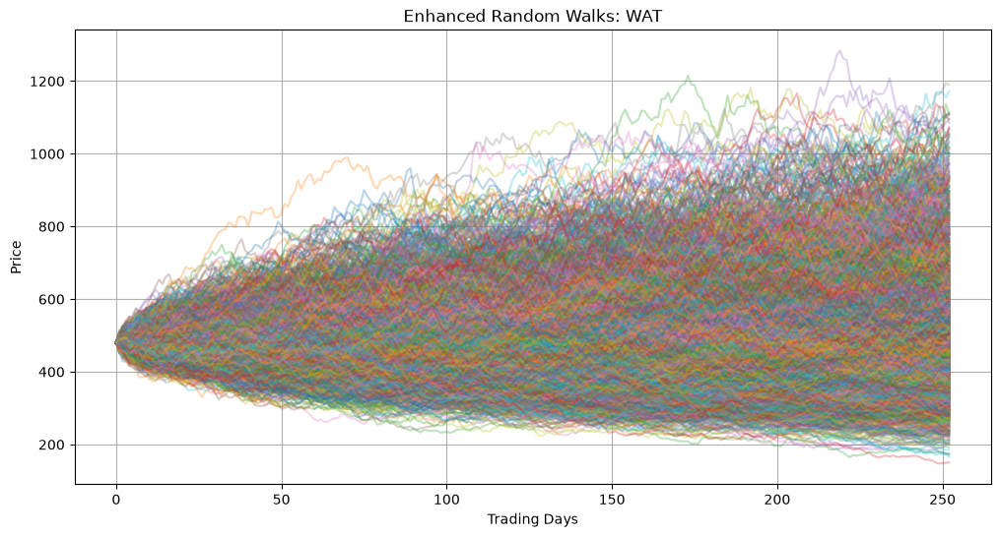

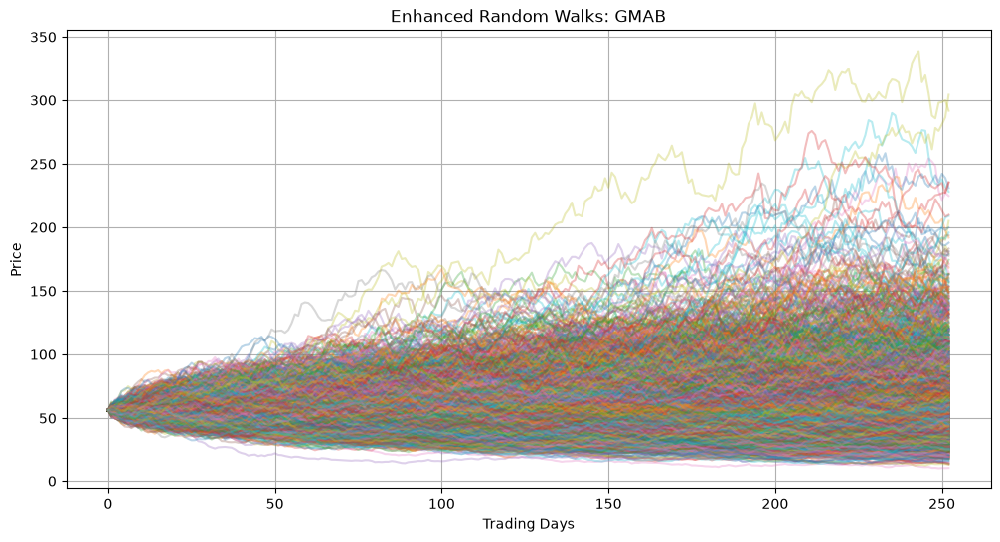

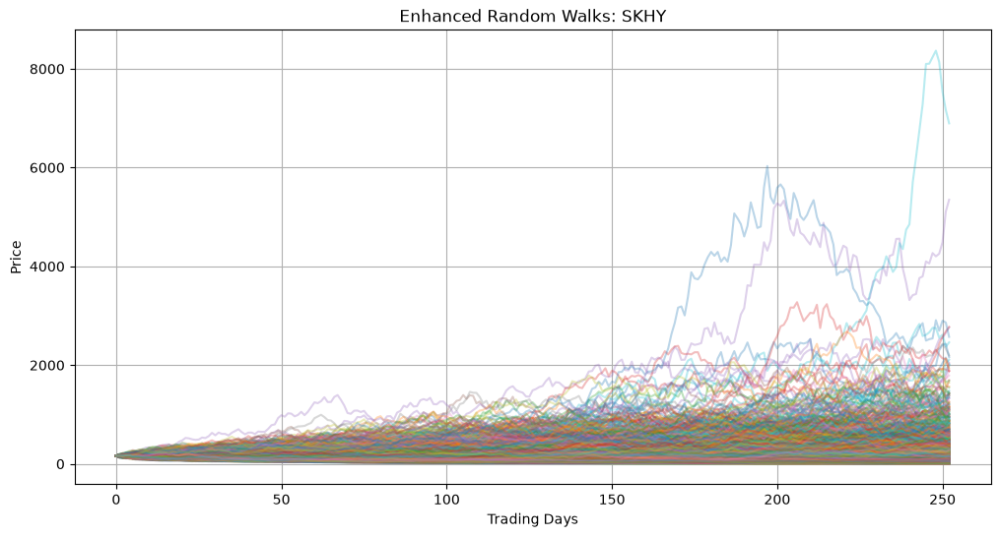

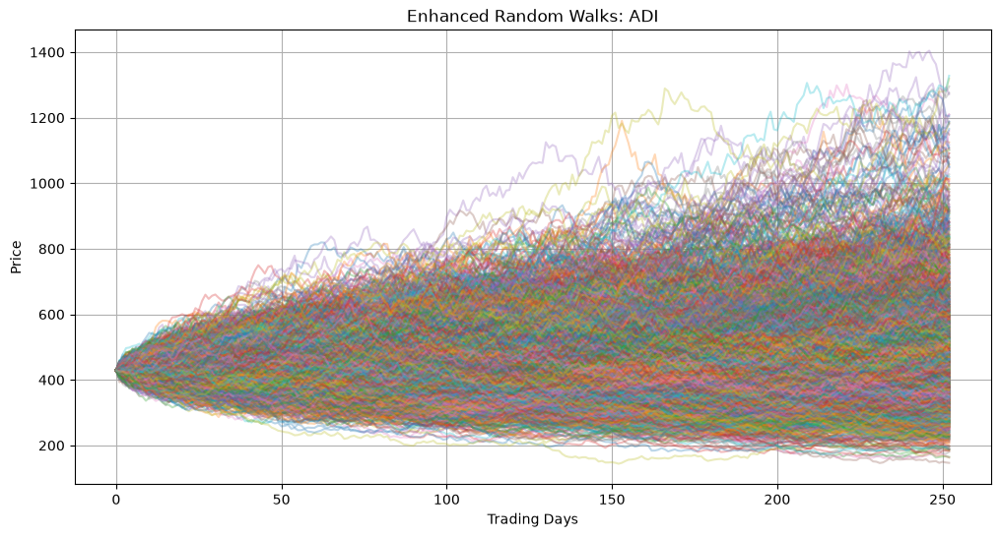

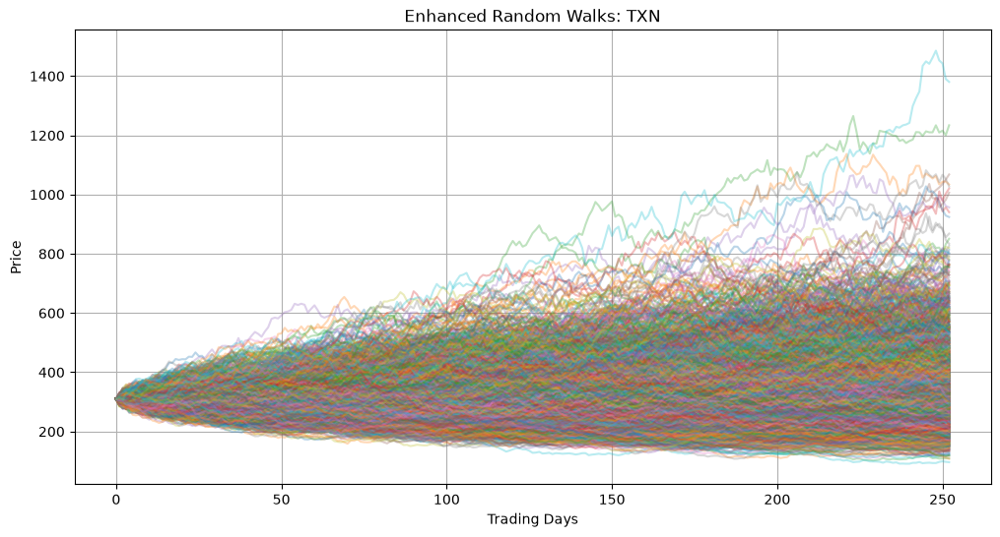

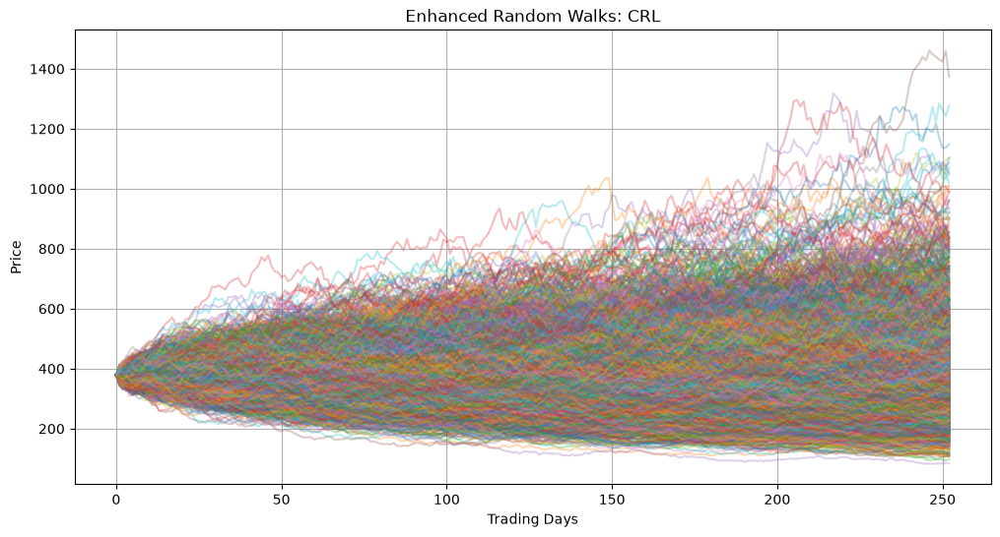

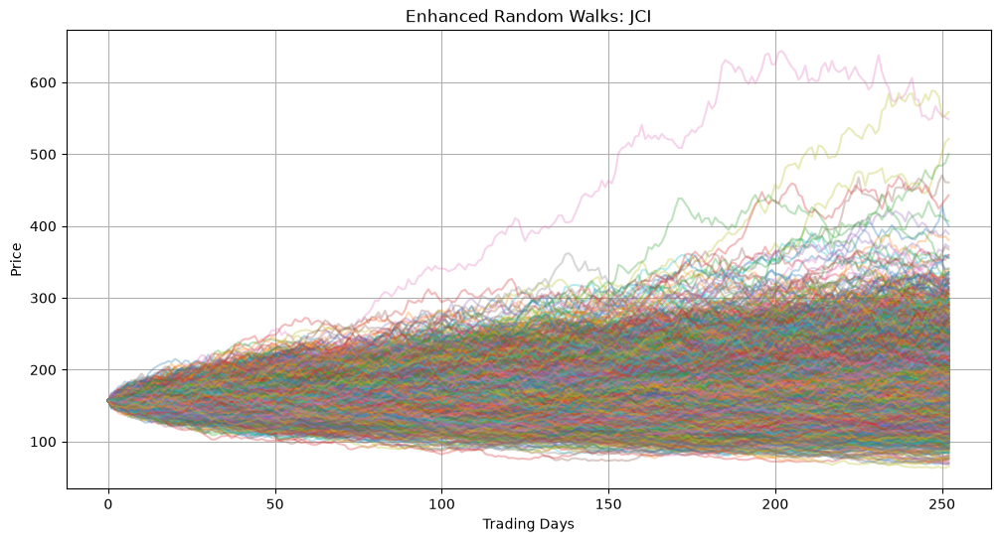

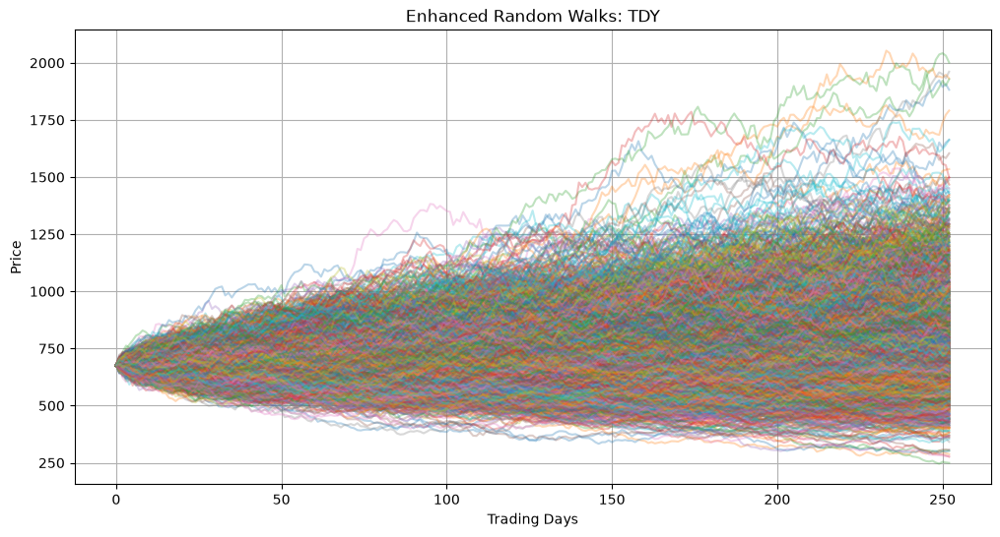

Enhanced simulations completed for: WAT, GMAB, SKHY, ADI, TXN, CRL, JCI, TDY


In [53]:
# --- 6: Enhanced Monte Carlo simulation for every stock ---
number_of_trials = 3000
number_of_trading_days = 252
enhanced_simulation_results = {}

for ticker_symbol, metrics in stock_metrics.items():
    ticker_closing_prices = []
    plt.figure(figsize=(12, 6))
    for i in range(number_of_trials):
        daily_returns = np.random.normal(metrics['blended_drift'] / number_of_trading_days, metrics['blended_volatility'] / math.sqrt(number_of_trading_days), number_of_trading_days) + 1
        price_series = [metrics['current_price']]
        for daily_return in daily_returns:
            price_series.append(price_series[-1] * daily_return)
        ticker_closing_prices.append(price_series[-1])
        plt.plot(price_series, alpha=0.3)

    enhanced_simulation_results[ticker_symbol] = ticker_closing_prices
    plt.title(f'Enhanced Random Walks: {ticker_symbol}')
    plt.xlabel('Trading Days')
    plt.ylabel('Price')
    plt.grid(True)
    plt.show()

print('Enhanced simulations completed for:', ', '.join(enhanced_simulation_results))


In [54]:
# --- 1-YEAR PRICE PROJECTION SUMMARY FOR EVERY STOCK ---
enhanced_projection_summary = {}
for ticker_symbol, closing_prices in enhanced_simulation_results.items():
    metrics = stock_metrics[ticker_symbol]
    current_price = metrics['current_price']
    projection_date = stock_name.index[-1] + pd.tseries.offsets.BDay(252)
    mean_price = float(np.mean(closing_prices))
    summary = {
        'current_price': current_price,
        'mean_price': mean_price,
        'p5': float(np.percentile(closing_prices, 5)),
        'p25': float(np.percentile(closing_prices, 25)),
        'p50': float(np.percentile(closing_prices, 50)),
        'p75': float(np.percentile(closing_prices, 75)),
        'p95': float(np.percentile(closing_prices, 95)),
        'prob_gain': float(np.mean(np.asarray(closing_prices) > current_price)),
        'projection_date': projection_date,
        'analyst_mean_1y': metrics['analyst_mean_1y'],
    }
    enhanced_projection_summary[ticker_symbol] = summary
    print('=' * 55)
    print(f"1-YEAR PRICE PROJECTION FOR {ticker_symbol}  ({projection_date.date()})")
    print('=' * 55)
    print(f"Current price:                 ${current_price:,.2f}")
    print(f"Expected (mean) price:         ${mean_price:,.2f}")
    print(f"Median (50th percentile):      ${summary['p50']:,.2f}")
    print(f"25th-75th percentile range:    ${summary['p25']:,.2f} - ${summary['p75']:,.2f}")
    print(f"5th-95th percentile range:     ${summary['p5']:,.2f} - ${summary['p95']:,.2f}")
    print(f"Probability of gain in 1 year: {summary['prob_gain']:.1%}")
    if summary['analyst_mean_1y']:
        print(f"Analyst mean 1y target:        ${summary['analyst_mean_1y']:,.2f}")


1-YEAR PRICE PROJECTION FOR WAT  (2027-10-18)
Current price:                 $480.96
Expected (mean) price:         $514.01
Median (50th percentile):      $493.54
25th-75th percentile range:    $391.32 - $610.02
5th-95th percentile range:     $287.51 - $831.51
Probability of gain in 1 year: 53.0%
Analyst mean 1y target:        $465.86
1-YEAR PRICE PROJECTION FOR GMAB  (2027-10-18)
Current price:                 $56.32
Expected (mean) price:         $62.92
Median (50th percentile):      $56.28
25th-75th percentile range:    $41.27 - $77.40
5th-95th percentile range:     $27.09 - $119.84
Probability of gain in 1 year: 49.9%
Analyst mean 1y target:        $61.15
1-YEAR PRICE PROJECTION FOR SKHY  (2027-10-18)
Current price:                 $162.99
Expected (mean) price:         $220.35
Median (50th percentile):      $131.53
25th-75th percentile range:    $66.32 - $266.23
5th-95th percentile range:     $23.07 - $701.06
Probability of gain in 1 year: 41.2%
Analyst mean 1y target:        $256

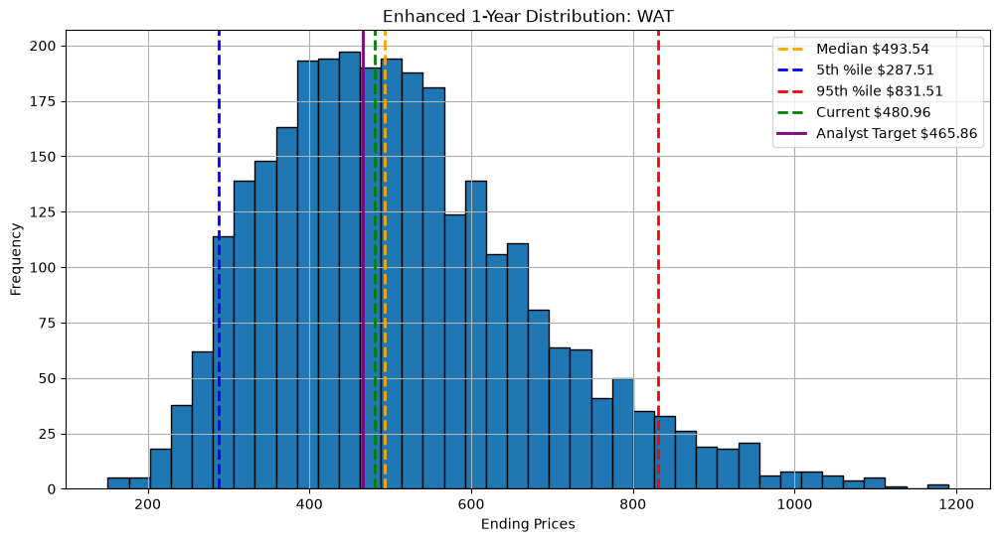

Saved WAT results to stock_simulation_data_WAT_enhanced.pkl


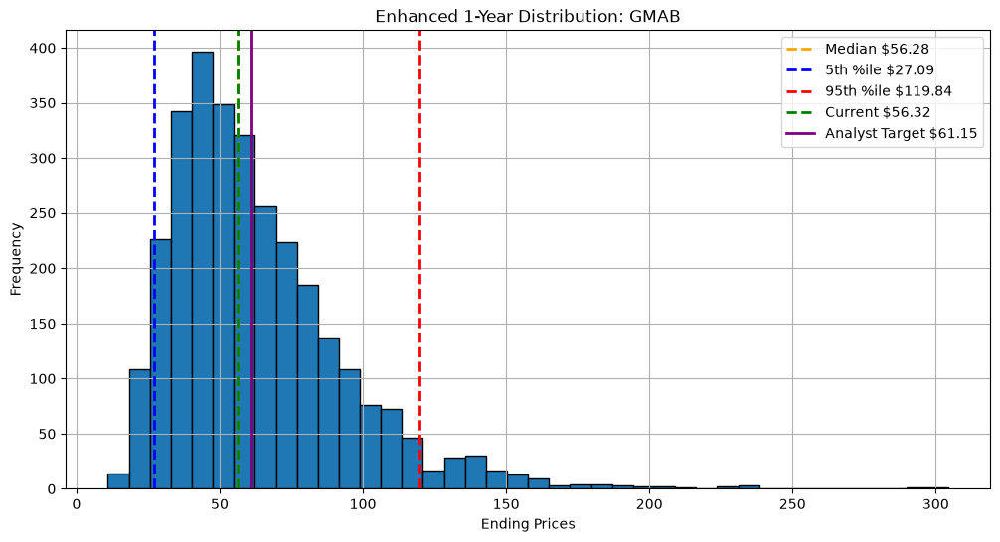

Saved GMAB results to stock_simulation_data_GMAB_enhanced.pkl


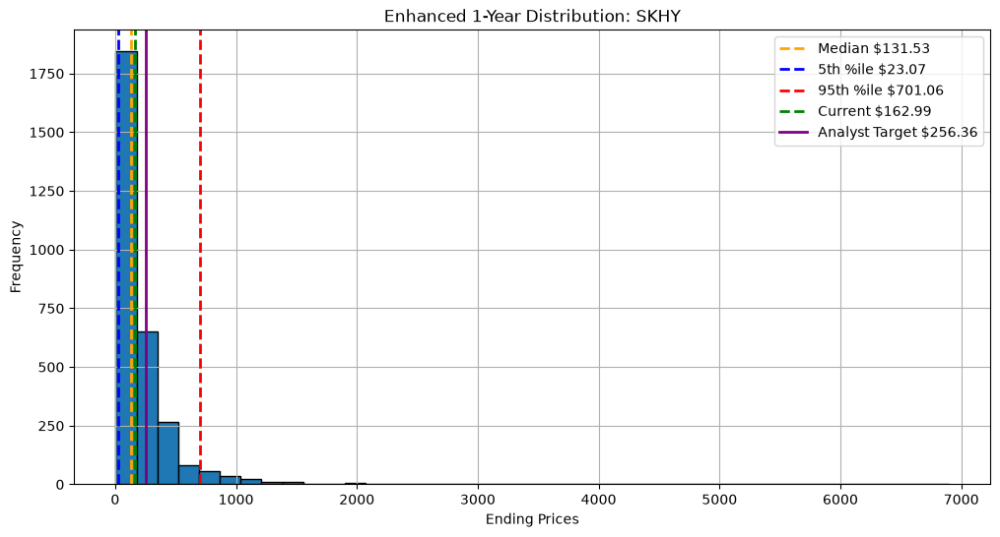

Saved SKHY results to stock_simulation_data_SKHY_enhanced.pkl


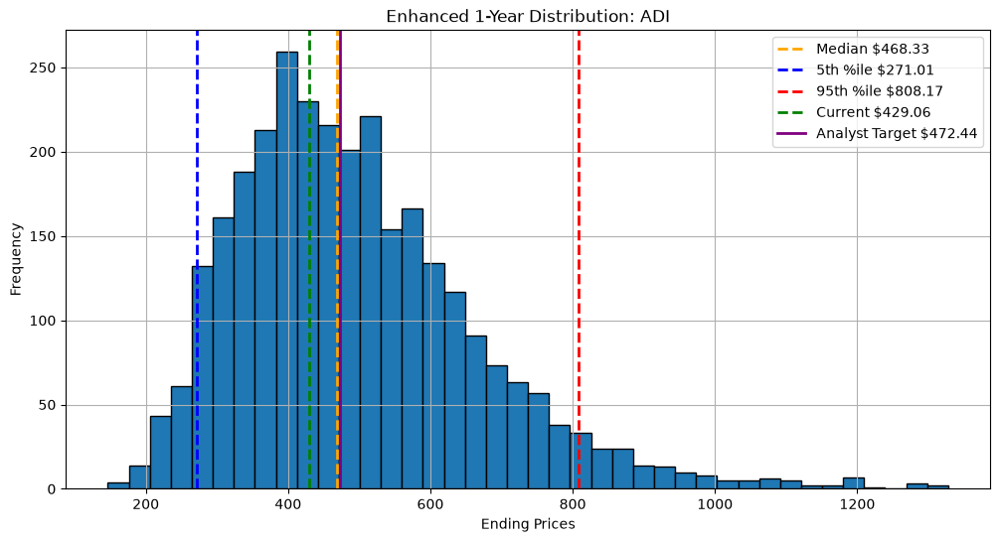

Saved ADI results to stock_simulation_data_ADI_enhanced.pkl


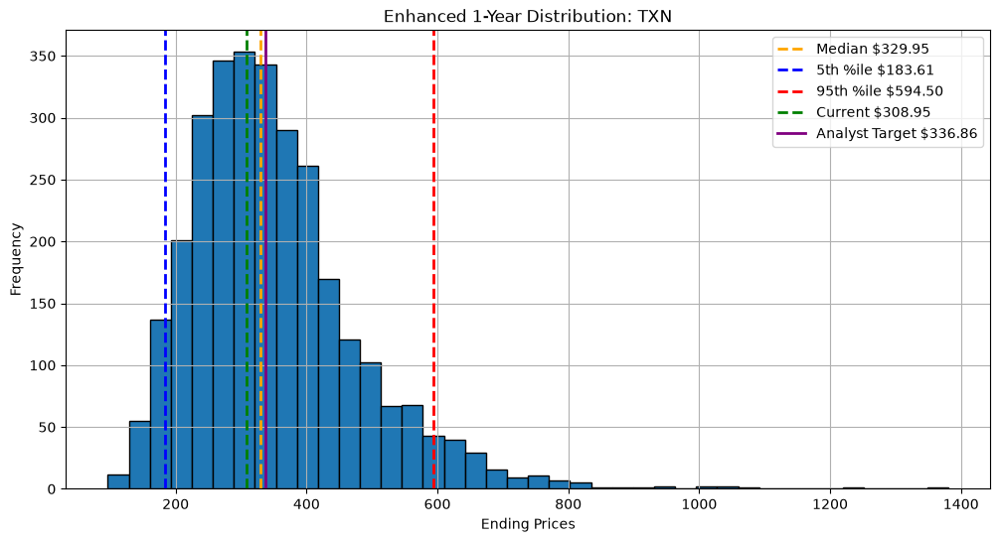

Saved TXN results to stock_simulation_data_TXN_enhanced.pkl


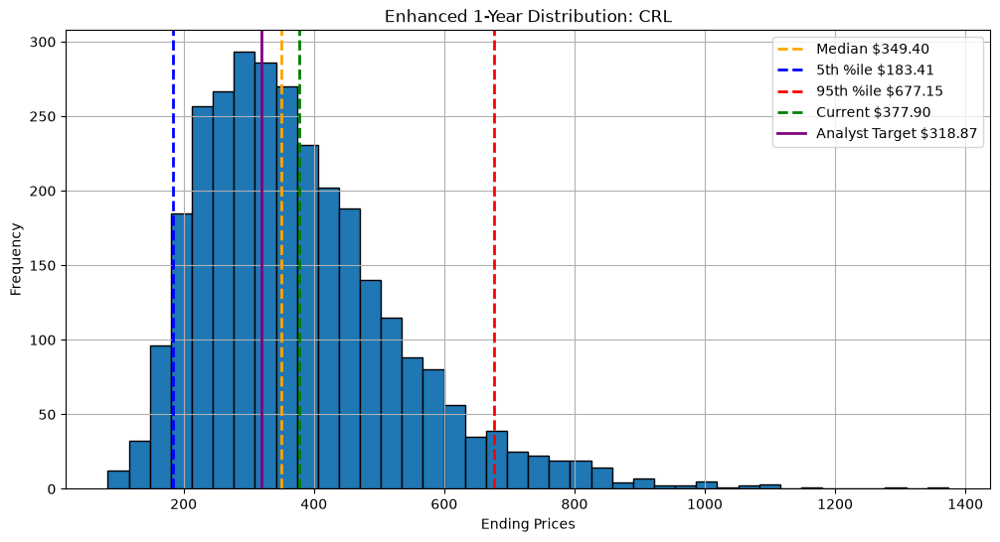

Saved CRL results to stock_simulation_data_CRL_enhanced.pkl


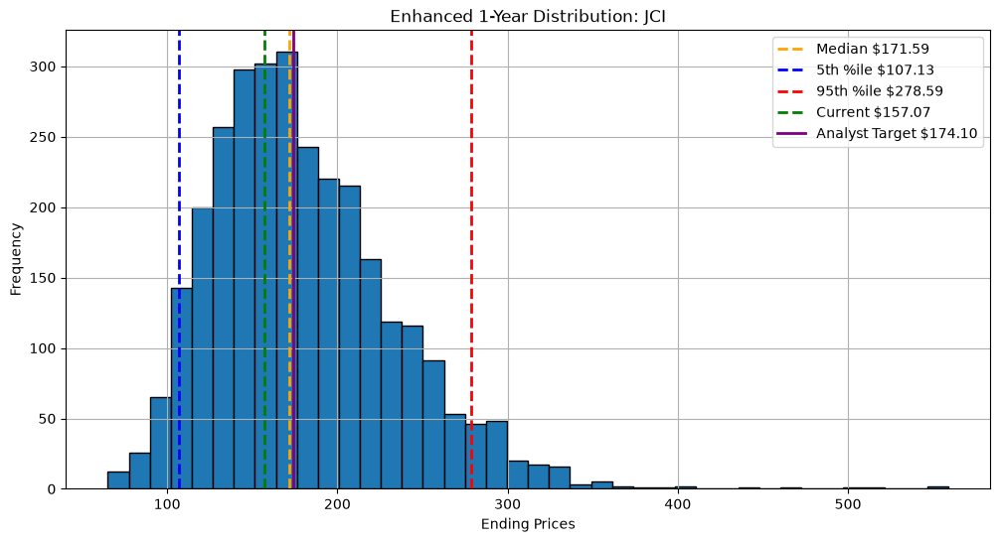

Saved JCI results to stock_simulation_data_JCI_enhanced.pkl


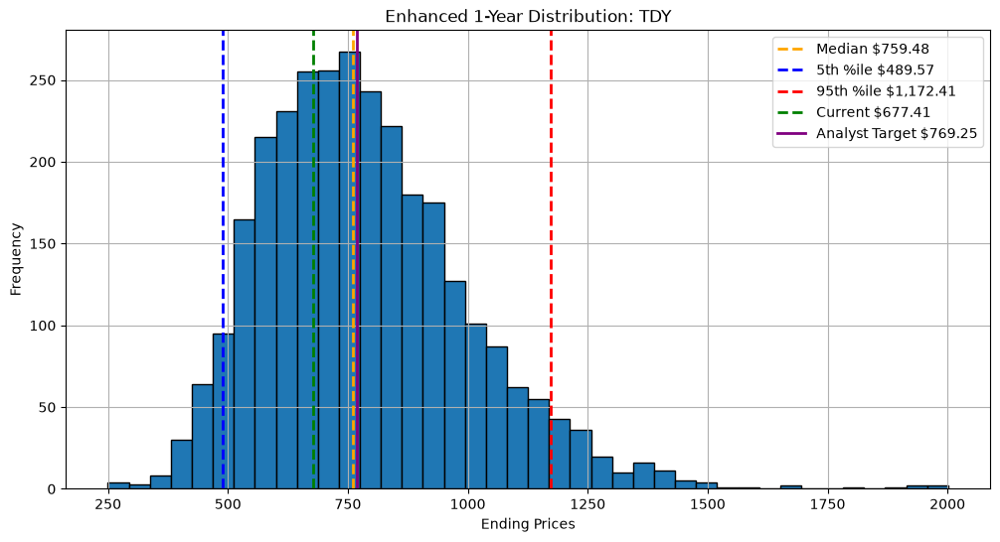

Saved TDY results to stock_simulation_data_TDY_enhanced.pkl


In [55]:
# --- Enhanced distributions and analyst overlays for every stock ---
enhanced_saved_files = {}
for ticker_symbol, closing_prices in enhanced_simulation_results.items():
    summary = enhanced_projection_summary[ticker_symbol]
    metrics = stock_metrics[ticker_symbol]
    current_price = metrics['current_price']
    plt.figure(figsize=(12, 6))
    plt.hist(closing_prices, bins=40, edgecolor='black')
    plt.axvline(summary['p50'], color='orange', linestyle='dashed', linewidth=2, label=f"Median ${summary['p50']:,.2f}")
    plt.axvline(summary['p5'], color='b', linestyle='dashed', linewidth=2, label=f"5th %ile ${summary['p5']:,.2f}")
    plt.axvline(summary['p95'], color='r', linestyle='dashed', linewidth=2, label=f"95th %ile ${summary['p95']:,.2f}")
    plt.axvline(current_price, color='g', linestyle='dashed', linewidth=2, label=f"Current ${current_price:,.2f}")
    if summary['analyst_mean_1y']:
        plt.axvline(summary['analyst_mean_1y'], color='purple', linewidth=2, label=f"Analyst Target ${summary['analyst_mean_1y']:,.2f}")
    plt.xlabel('Ending Prices')
    plt.ylabel('Frequency')
    plt.title(f"Enhanced 1-Year Distribution: {ticker_symbol}")
    plt.legend()
    plt.grid(True)
    filename = f'histogram_enhanced_{ticker_symbol}.png'
    plt.savefig(filename)
    enhanced_saved_files[ticker_symbol] = filename
    plt.show()

    enhanced_data = {
        'enhanced_closing_prices': closing_prices,
        'summary': summary,
        'fundamentals': fundamentals_by_ticker.get(ticker_symbol, {}),
        'blended_drift': metrics['blended_drift'],
        'blended_volatility': metrics['blended_volatility'],
    }
    pickle_filename = f'stock_simulation_data_{ticker_symbol}_enhanced.pkl'
    with open(pickle_filename, 'wb') as f:
        pickle.dump(enhanced_data, f)
    print(f"Saved {ticker_symbol} results to {pickle_filename}")


In [56]:
for ticker_symbol, summary in enhanced_projection_summary.items():
    current_price = summary["current_price"]
    proj_pct = (summary["mean_price"] / current_price - 1) * 100
    print(f"Stock: {ticker_symbol}")
    print(f"Calculated 1-year projected price ({summary['projection_date'].date()}): ${summary['mean_price']:,.2f} ({proj_pct:+.2f}%)")
    if summary["analyst_mean_1y"]:
        analyst_pct = (summary["analyst_mean_1y"] / current_price - 1) * 100
        print(f"Analyst 1-year target price: ${summary['analyst_mean_1y']:,.2f} ({analyst_pct:+.2f}%)")
    else:
        print("Analyst 1-year target price: N/A")


Stock: WAT
Calculated 1-year projected price (2027-10-18): $514.01 (+6.87%)
Analyst 1-year target price: $465.86 (-3.14%)
Stock: GMAB
Calculated 1-year projected price (2027-10-18): $62.92 (+11.71%)
Analyst 1-year target price: $61.15 (+8.58%)
Stock: SKHY
Calculated 1-year projected price (2027-10-18): $220.35 (+35.20%)
Analyst 1-year target price: $256.36 (+57.29%)
Stock: ADI
Calculated 1-year projected price (2027-10-18): $494.78 (+15.32%)
Analyst 1-year target price: $472.44 (+10.11%)
Stock: TXN
Calculated 1-year projected price (2027-10-18): $349.82 (+13.23%)
Analyst 1-year target price: $336.86 (+9.04%)
Stock: CRL
Calculated 1-year projected price (2027-10-18): $378.01 (+0.03%)
Analyst 1-year target price: $318.87 (-15.62%)
Stock: JCI
Calculated 1-year projected price (2027-10-18): $179.96 (+14.57%)
Analyst 1-year target price: $174.10 (+10.85%)
Stock: TDY
Calculated 1-year projected price (2027-10-18): $785.13 (+15.90%)
Analyst 1-year target price: $769.25 (+13.56%)


# US Stock Screener — Top 15 by Projected 1-Year Return
Runs the enhanced Monte Carlo projection (blended drift = 50% historical CAGR + 50% analyst-implied return) across a large list of liquid US stocks, then ranks them by projected 1-year return.

Notes:
- "All US stocks" (6000+) would take hours to download; this screens a curated universe of S&P 500 + major tech/growth names. Extend `TICKERS` as needed.
- Requires internet; yfinance rate limits may throttle long runs. Progress is printed.
- Results include: current price, projected 1yr price, projected % return, analyst mean target, and probability of gain.

In [112]:
def _read_tables(url):
    """Read HTML tables from a URL (Wikipedia blocks default urllib, so use requests + UA header)."""
    import io
    import pandas as pd
    html = requests.get(url, headers={'User-Agent': 'Mozilla/5.0'}).text
    return pd.read_html(io.StringIO(html))


def get_nasdaq100_tickers():
    url = 'https://en.wikipedia.org/wiki/List_of_NASDAQ-100_companies'
    for t in _read_tables(url):
        # Wikipedia has used both 'Ticker' and 'Symbol' as the column name
        for col in ('Ticker', 'Symbol'):
            if col in t.columns:
                return t[col].astype(str).str.replace('.', '-', regex=False).tolist()
    return []


def get_sp500_tickers():
    url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
    for t in _read_tables(url):
        for col in ('Symbol', 'Ticker'):
            if col in t.columns:
                return t[col].astype(str).str.replace('.', '-', regex=False).tolist()
    return []

In [113]:
import pandas as pd


def screen_ticker(tkr, trials=1000, verbose=False):
    """Run the enhanced MC projection for one ticker. Returns a dict or None on failure."""
    try:
        data = yf.download(tkr, start='2009-01-01', progress=False)
        if data is None or len(data) < 260:
            if verbose:
                print(f"  {tkr}: download returned {0 if data is None else len(data)} rows")
            return None
        close = data[('Close', tkr)] if ('Close', tkr) in data.columns else data['Close']
        close = close.dropna()
        if len(close) < 260:
            return None

        # Historical stats
        growth = close.iloc[-1] / close.iloc[0]
        years = (close.index[-1] - close.index[0]).days / 365.0
        if years <= 0:
            return None
        cagr_t = (growth ** (1/years)) - 1
        vol_long = close.pct_change().std() * math.sqrt(252)
        # Series.last() was removed in pandas 3.x — use a date slice instead
        recent = close[close.index >= close.index[-1] - pd.DateOffset(years=2)]
        vol_recent = recent.pct_change().std() * math.sqrt(252)
        vol = 0.5 * vol_long + 0.5 * (
            vol_recent if not math.isnan(vol_recent) else vol_long
        )

        if math.isnan(vol_long) or math.isnan(vol):
            return None

        current = float(close.iloc[-1])
        try:
            analyst_target = yf.Ticker(tkr).info.get('targetMeanPrice')
        except Exception:
            analyst_target = None

        analyst_return = None
        if analyst_target is not None and float(analyst_target) > 0:
            analyst_target = float(analyst_target)
            analyst_return = analyst_target / current - 1

        drift = 0.5 * cagr_t + 0.5 * analyst_return if analyst_return is not None else cagr_t

        endings = []
        for _ in range(trials):
            daily_returns = np.random.normal(
                drift / 252,
                vol / math.sqrt(252),
                252
            ) + 1
            projected_price = current
            for daily_return in daily_returns:
                projected_price *= daily_return
            endings.append(projected_price)

        projected_1y = float(np.mean(endings))
        return {
            'ticker': tkr,
            'current': current,
            'projected_1y': projected_1y,
            'proj_return_pct': (projected_1y / current - 1) * 100,
            'analyst_target': analyst_target,
            'prob_gain_pct': 100 * np.mean(np.asarray(endings) > current),
        }
    except Exception as exc:
        if verbose:
            print(f"  {tkr}: {exc}")
        return None

In [114]:
# --- Quick diagnostic: run 2 tickers with verbose errors ---
for t in ['AAPL', 'MSFT']:
    screen_ticker(t, verbose=True)
print("Diagnostic done. If both printed 'download returned 0 rows', you are rate-limited — wait 15-30 min.")


c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#depreca

Diagnostic done. If both printed 'download returned 0 rows', you are rate-limited — wait 15-30 min.


In [115]:
# --- Build the screening universe and run the screener -> `results` ---
TICKERS = sorted(set(get_sp500_tickers() + get_nasdaq100_tickers()))
print(f"Screening {len(TICKERS)} tickers (this can take a while)...")

results = []
for i, tkr in enumerate(TICKERS, 1):
    r = screen_ticker(tkr)
    if r:
        results.append(r)
    if i % 50 == 0 or i == len(TICKERS):
        print(f"  {i}/{len(TICKERS)} done — {len(results)} successful")

print(f"Screen complete: {len(results)}/{len(TICKERS)} tickers produced results")

Screening 518 tickers (this can take a while)...


c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#depreca

  50/518 done — 50 successful


c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#depreca

  100/518 done — 100 successful


c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#depreca

... (13 outputs left out)

c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#depreca

  500/518 done — 495 successful


c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\prasa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#depreca

  518/518 done — 513 successful
Screen complete: 513/518 tickers produced results


In [116]:
# --- Top 15 by projected 1-year return ---
top15 = sorted(results, key=lambda x: x['proj_return_pct'], reverse=True)[:15]

print("=" * 80)
print("TOP 15 US STOCKS BY PROJECTED 1-YEAR RETURN")
print("=" * 80)
print(f"{'#':>2} {'Ticker':<7} {'Current':>10} {'Proj 1Y':>10} {'Proj %':>9} {'Analyst Tgt':>12} {'P(gain)':>8}")
print("-" * 80)
for rank, r in enumerate(top15, 1):
    atgt = f"${r['analyst_target']:,.2f}" if r['analyst_target'] else "N/A"
    print(f"{rank:>2} {r['ticker']:<7} ${r['current']:>9,.2f} ${r['projected_1y']:>9,.2f} "
          f"{r['proj_return_pct']:>+8.1f}% {atgt:>12} {r['prob_gain_pct']:>7.1f}%")
print("=" * 80)

# As a DataFrame
import pandas as pd
top15_df = pd.DataFrame(top15)
display(top15_df)


TOP 15 US STOCKS BY PROJECTED 1-YEAR RETURN
 # Ticker     Current    Proj 1Y    Proj %  Analyst Tgt  P(gain)
--------------------------------------------------------------------------------
 1 SNDK    $ 1,369.43 $75,162.50  +5388.6%    $2,143.83   100.0%
 2 NBIS    $   176.98 $   686.12   +287.7%      $281.00    70.9%
 3 GEV     $   905.51 $ 1,825.74   +101.6%    $1,216.91    85.8%
 4 CRWV    $    64.04 $   119.23    +86.2%      $134.58    51.8%
 5 APP     $   258.41 $   467.05    +80.7%      $469.27    63.3%
 6 ALAB    $   293.00 $   517.46    +76.6%      $382.68    57.1%
 7 RDDT    $   129.93 $   221.84    +70.7%      $212.95    61.8%
 8 RKLB    $    60.90 $   103.27    +69.6%      $102.15    59.2%
 9 ALNY    $   191.26 $   324.17    +69.5%      $367.78    78.0%
10 NVDA    $   214.05 $   357.53    +67.0%      $328.95    81.0%
11 MU      $   948.43 $ 1,557.78    +64.2%    $1,561.91    68.8%
12 FLEX    $    94.53 $   150.11    +58.8%      $155.90    72.8%
13 AXON    $   430.47 $   672.

,ticker,current,projected_1y,proj_return_pct,analyst_target,prob_gain_pct
0,SNDK,1369.430054,75162.501680,5388.597353,2143.83330,100.0
1,NBIS,176.979996,686.119748,287.682091,281.00000,70.9
2,GEV,905.505005,1825.742443,101.626985,1216.90900,85.8
3,CRWV,64.040001,119.228947,86.178866,134.57895,51.8
4,APP,258.410004,467.053047,80.741086,469.27130,63.3
5,ALAB,293.000000,517.455758,76.606061,382.67780,57.1
6,RDDT,129.929993,221.838947,70.737289,212.95152,61.8
7,RKLB,60.900002,103.274021,69.579669,102.15000,59.2
8,ALNY,191.259995,324.170333,69.491970,367.77777,78.0
9,NVDA,214.050003,357.529890,67.031014,328.95346,81.0
